##### SURVIVAL PREDICTION MODEL

##### THE PREDICTION PROBLEM
Predict  whether the lung-cancer patient survives based on their demographic, clinical, lifestyle, and treatment-related variables.

In [1]:
# TRAGET -> survived column

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
file_path = r"C:\Users\Lenove\Documents\Project_01_ML01\lungcancerdata.xlsx"
data = pd.read_excel(file_path, nrows=10000)
data

,id,age,gender,country,diagnosis_date,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type,end_treatment_date,survived
0,1,64,Male,Sweden,2016-04-05,Stage I,Yes,Passive Smoker,29.4,199,0,0,1,0,Chemotherapy,end_treatment_date,0
1,2,50,Female,Netherlands,2023-04-20,Stage III,Yes,Passive Smoker,41.2,280,1,1,0,0,Surgery,end_treatment_date,1
2,3,65,Female,Hungary,2023-04-05,Stage III,Yes,Former Smoker,44.0,268,1,1,0,0,Combined,end_treatment_date,0
3,4,51,Female,Belgium,2016-02-05,Stage I,No,Passive Smoker,43.0,241,1,1,0,0,Chemotherapy,end_treatment_date,0
4,5,37,Male,Luxembourg,2023-11-29,Stage I,No,Passive Smoker,19.7,178,0,0,0,0,Combined,end_treatment_date,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,65,Male,Cyprus,2024-05-10,Stage I,Yes,Passive Smoker,33.9,277,1,1,0,0,Combined,end_treatment_date,1
9996,9997,61,Female,Malta,2015-09-30,Stage I,No,Current Smoker,33.2,282,1,0,0,0,Surgery,end_treatment_date,0
9997,9998,52,Male,Sweden,2022-11-10,Stage I,No,Passive Smoker,27.0,156,1,0,0,0,Radiation,end_treatment_date,1
9998,9999,69,Male,Netherlands,2021-03-23,Stage IV,No,Former Smoker,42.6,261,1,1,1,0,Surgery,end_treatment_date,0


###### DATA INSPECTION

In [4]:
df = data.copy()

In [5]:
df = df.drop(columns = ["end_treatment_date"])

In [6]:
# shape of the dataset
df.shape

(10000, 16)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 10000 non-null  int64         
 1   age                10000 non-null  int64         
 2   gender             10000 non-null  str           
 3   country            10000 non-null  str           
 4   diagnosis_date     10000 non-null  datetime64[us]
 5   cancer_stage       10000 non-null  str           
 6   family_history     10000 non-null  str           
 7   smoking_status     10000 non-null  str           
 8   bmi                10000 non-null  float64       
 9   cholesterol_level  10000 non-null  int64         
 10  hypertension       10000 non-null  int64         
 11  asthma             10000 non-null  int64         
 12  cirrhosis          10000 non-null  int64         
 13  other_cancer       10000 non-null  int64         
 14  treatment_type    

In [8]:
 df.columns

Index(['id', 'age', 'gender', 'country', 'diagnosis_date', 'cancer_stage',
       'family_history', 'smoking_status', 'bmi', 'cholesterol_level',
       'hypertension', 'asthma', 'cirrhosis', 'other_cancer', 'treatment_type',
       'survived'],
      dtype='str')

In [9]:
# Check the dataset for survived patients and non-survived patients
df["survived"].value_counts()

survived
0    7762
1    2238
Name: count, dtype: int64

In [10]:
# Check for missing values
df.isnull().sum()

id                   0
age                  0
gender               0
country              0
diagnosis_date       0
cancer_stage         0
family_history       0
smoking_status       0
bmi                  0
cholesterol_level    0
hypertension         0
asthma               0
cirrhosis            0
other_cancer         0
treatment_type       0
survived             0
dtype: int64

In [11]:
# check for missing percentage
missing_percentage = df.isnull().mean()*100
missing_percentage.sort_values(ascending=False)

id                   0.0
age                  0.0
gender               0.0
country              0.0
diagnosis_date       0.0
cancer_stage         0.0
family_history       0.0
smoking_status       0.0
bmi                  0.0
cholesterol_level    0.0
hypertension         0.0
asthma               0.0
cirrhosis            0.0
other_cancer         0.0
treatment_type       0.0
survived             0.0
dtype: float64

###### TARGET IDENTIFICATION

In [12]:
df.columns.tolist()

['id',
 'age',
 'gender',
 'country',
 'diagnosis_date',
 'cancer_stage',
 'family_history',
 'smoking_status',
 'bmi',
 'cholesterol_level',
 'hypertension',
 'asthma',
 'cirrhosis',
 'other_cancer',
 'treatment_type',
 'survived']

In [13]:
# separate the features and target variable
x = df.drop(columns=["survived", "id"])
y = df["survived"]

In [14]:
# Check the data types
x.dtypes

age                           int64
gender                          str
country                         str
diagnosis_date       datetime64[us]
cancer_stage                    str
family_history                  str
smoking_status                  str
bmi                         float64
cholesterol_level             int64
hypertension                  int64
asthma                        int64
cirrhosis                     int64
other_cancer                  int64
treatment_type                  str
dtype: object

In [15]:
y.dtypes

dtype('int64')

In [16]:
# Handle date columns
x["diagnosis_date"] = pd.to_datetime(x["diagnosis_date"], errors='coerce')
x

,age,gender,country,diagnosis_date,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type
0,64,Male,Sweden,2016-04-05,Stage I,Yes,Passive Smoker,29.4,199,0,0,1,0,Chemotherapy
1,50,Female,Netherlands,2023-04-20,Stage III,Yes,Passive Smoker,41.2,280,1,1,0,0,Surgery
2,65,Female,Hungary,2023-04-05,Stage III,Yes,Former Smoker,44.0,268,1,1,0,0,Combined
3,51,Female,Belgium,2016-02-05,Stage I,No,Passive Smoker,43.0,241,1,1,0,0,Chemotherapy
4,37,Male,Luxembourg,2023-11-29,Stage I,No,Passive Smoker,19.7,178,0,0,0,0,Combined
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,65,Male,Cyprus,2024-05-10,Stage I,Yes,Passive Smoker,33.9,277,1,1,0,0,Combined
9996,61,Female,Malta,2015-09-30,Stage I,No,Current Smoker,33.2,282,1,0,0,0,Surgery
9997,52,Male,Sweden,2022-11-10,Stage I,No,Passive Smoker,27.0,156,1,0,0,0,Radiation
9998,69,Male,Netherlands,2021-03-23,Stage IV,No,Former Smoker,42.6,261,1,1,1,0,Surgery


In [17]:
x["diagnosis_year"] = x["diagnosis_date"].dt.year
x["diagnosis_month"] = x["diagnosis_date"].dt.month


In [18]:
x = x.drop(columns=["diagnosis_date"])

In [19]:
x.dtypes

age                    int64
gender                   str
country                  str
cancer_stage             str
family_history           str
smoking_status           str
bmi                  float64
cholesterol_level      int64
hypertension           int64
asthma                 int64
cirrhosis              int64
other_cancer           int64
treatment_type           str
diagnosis_year         int32
diagnosis_month        int32
dtype: object

###### TARGET ENCODING

In [20]:
y.unique()
y.value_counts()

survived
0    7762
1    2238
Name: count, dtype: int64

In [21]:
for col in x.columns:
    if x[col].dtype == "object":
        converted = pd.to_numeric(x[col], errors="coerce")

        # Keep the column numeric only if every non-missing
        # original value can be converted to a number.
        original_nonmissing = x[col].notna()
        if converted[original_nonmissing].notna().all():
            x[col] = converted
        else:
            x[col] = x[col].astype("string")

numeric_cols = x.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = x.select_dtypes(
    include=["category", "bool", "string"]
).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)


Numerical columns: ['age', 'bmi', 'cholesterol_level', 'hypertension', 'asthma', 'cirrhosis', 'other_cancer', 'diagnosis_year', 'diagnosis_month']
Categorical columns: ['gender', 'country', 'cancer_stage', 'family_history', 'smoking_status', 'treatment_type']


###### TRAIN/TEST SPLIT

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [23]:
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.2, random_state=42, stratify=y)

x_train.shape, x_test.shape, y_train.shape, y_test.shape    

((8000, 15), (2000, 15), (8000,), (2000,))

###### DATA PREPROCESSING

In [24]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [25]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_cols
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ]
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

###### LOGISTIC REGRESSION

In [26]:
# Create the model pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

logistic_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [27]:
logistic_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','gender','country',...,'treatment_type','diagnosis_year', 'diagnosis_month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [28]:
# Make predictions 
y_pred = logistic_model.predict(x_test)
y_pred

array([0, 0, 1, ..., 0, 0, 1], shape=(2000,))

In [29]:
y_prob = logistic_model.predict_proba(x_test)[:, 1]
y_prob

array([0.48192948, 0.45953898, 0.56436765, ..., 0.48217303, 0.42791482,
       0.53655624], shape=(2000,))

In [30]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred , zero_division=0)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.5345
Precision: 0.23255813953488372
Recall   : 0.46875
F1 Score : 0.31088082901554404
ROC-AUC  : 0.5157285530191458


In [31]:
print(y_train.value_counts())
print(y_test.value_counts())

survived
0    6210
1    1790
Name: count, dtype: int64
survived
0    1552
1     448
Name: count, dtype: int64


In [32]:
print("Predicted classes:")
print(np.unique(y_pred, return_counts=True))

Predicted classes:
(array([0, 1]), array([1097,  903]))


In [33]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
survived
0    6210
1    1790
Name: count, dtype: int64

Testing target distribution:
survived
0    1552
1     448
Name: count, dtype: int64


In [34]:
y_prob = logistic_model.predict_proba(x_test)[:, 1]

print("Minimum probability:", y_prob.min())
print("Maximum probability:", y_prob.max())
print("Mean probability:", y_prob.mean())

print("\nFirst 10 probabilities:")
print(y_prob[:10])

Minimum probability: 0.36414202436193294
Maximum probability: 0.6305252490169859
Mean probability: 0.49670237251821653

First 10 probabilities:
[0.48192948 0.45953898 0.56436765 0.5832783  0.55672254 0.44326668
 0.47797495 0.53124427 0.47361546 0.46435877]


In [35]:
print(y_train.value_counts())

survived
0    6210
1    1790
Name: count, dtype: int64


In [36]:
classification_report = pd.crosstab(y_test, 
                      y_pred)
classification_report


col_0,0,1
survived,,
0,859,693
1,238,210


###### CONFUSION MATRIX ( LOGISTIC REGRESSION)

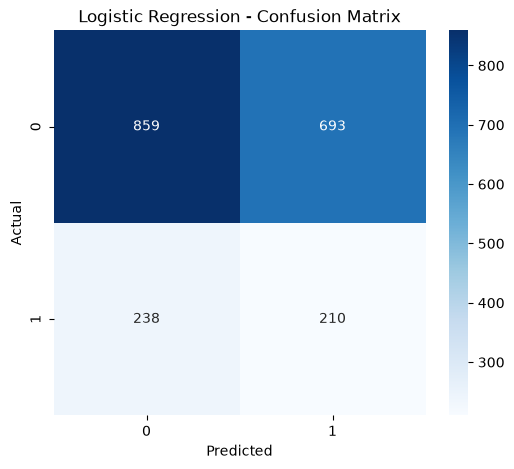

In [37]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

#####  RANDOM FOREST

In [38]:
# Create random forest model pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=50,
            max_depth=10,
            min_samples_split=2,            
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ]
)

random_forest_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [39]:
random_forest_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','gender','country',...,'treatment_type','diagnosis_year', 'diagnosis_month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [40]:
# Make predictions on the test set
rf_pred = random_forest_model.predict(x_test)
rf_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(2000,))

In [41]:
rf_prob = random_forest_model.predict_proba(x_test)[:, 1]
rf_prob

array([0.45078809, 0.41839104, 0.45984722, ..., 0.47822753, 0.36593105,
       0.37496093], shape=(2000,))

In [42]:
# Evaluate the random forest model
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

Random Forest Results
---------------------
Accuracy : 0.646
Precision: 0.24308300395256918
Recall   : 0.27455357142857145
F1 Score : 0.2578616352201258
ROC-AUC  : 0.5143838020066275


In [43]:
classification_report = pd.crosstab(y_test, rf_pred)
classification_report 

col_0,0,1
survived,,
0,1169,383
1,325,123


##### CONFUSION MATRIX( RANDOM FOREST)

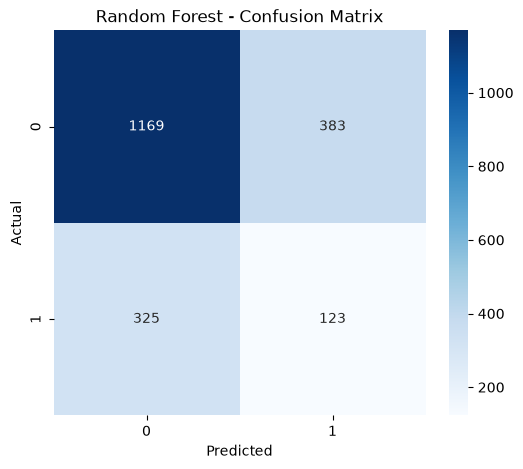

In [44]:
# Random Forest Confusion Matrix
cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.show()

##### MODEL COMPARISON

In [45]:
# Compare the models
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy
    ],
    "Precision": [
        precision,
        rf_precision
    ],
    "Recall": [
        recall,
        rf_recall
    ],
    "F1 Score": [
        f1,
        rf_f1
    ],
    "ROC-AUC": [
        roc_auc,
        rf_roc_auc
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.5345,0.232558,0.468750,0.310881,0.515729
1,Random Forest,0.6460,0.243083,0.274554,0.257862,0.514384


##### FEATURE IMPORTANCE

In [46]:
# Get trained random forest
rf = random_forest_model.named_steps["classifier"]
rf

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featu

In [47]:
# Get the preprocessing transformer
preprocessor_fitted = random_forest_model.named_steps["preprocessor"]
preprocessor_fitted

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [48]:
# Get the transformed feature names
feature_names = preprocessor_fitted.get_feature_names_out()

print("Number of features:", len(feature_names))

Number of features: 52


In [49]:
# Extract feature importances
importance = rf.feature_importances_
importance

array([0.1066576 , 0.12517468, 0.11528628, 0.01738204, 0.01909818,
       0.0174851 , 0.01547392, 0.0801559 , 0.07572274, 0.01517945,
       0.01847324, 0.00667065, 0.00602032, 0.00552647, 0.00710686,
       0.00645515, 0.00574436, 0.00553549, 0.00547421, 0.00505274,
       0.00578922, 0.00524658, 0.00709203, 0.00689563, 0.00800296,
       0.00485933, 0.00715673, 0.0054386 , 0.00601432, 0.0080942 ,
       0.00769174, 0.00615207, 0.00574147, 0.00527384, 0.00723294,
       0.00626986, 0.00835677, 0.00728663, 0.01554231, 0.01968231,
       0.01437562, 0.01823374, 0.01433527, 0.01612453, 0.01528713,
       0.01464492, 0.01509049, 0.01572534, 0.01585314, 0.01638396,
       0.01691781, 0.01353313])

In [50]:
# create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance

,Feature,Importance
0,num__age,0.106658
1,num__bmi,0.125175
2,num__cholesterol_level,0.115286
3,num__hypertension,0.017382
4,num__asthma,0.019098
5,num__cirrhosis,0.017485
6,num__other_cancer,0.015474
7,num__diagnosis_year,0.080156
8,num__diagnosis_month,0.075723
9,cat__gender_Female,0.015179


In [51]:
# Sort values by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
1,num__bmi,0.125175
2,num__cholesterol_level,0.115286
0,num__age,0.106658
7,num__diagnosis_year,0.080156
8,num__diagnosis_month,0.075723
39,cat__cancer_stage_Stage II,0.019682
4,num__asthma,0.019098
10,cat__gender_Male,0.018473
41,cat__cancer_stage_Stage IV,0.018234
5,num__cirrhosis,0.017485


In [52]:
feature_importance.head(15)

,Feature,Importance
1,num__bmi,0.125175
2,num__cholesterol_level,0.115286
0,num__age,0.106658
7,num__diagnosis_year,0.080156
8,num__diagnosis_month,0.075723
39,cat__cancer_stage_Stage II,0.019682
4,num__asthma,0.019098
10,cat__gender_Male,0.018473
41,cat__cancer_stage_Stage IV,0.018234
5,num__cirrhosis,0.017485


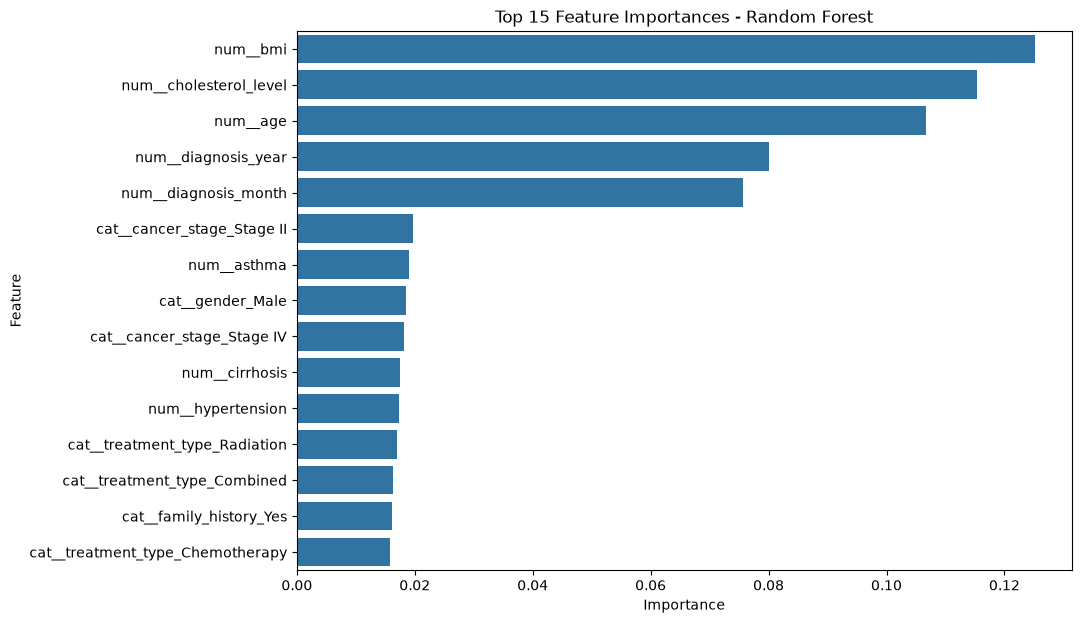

In [53]:
# Visualize feature importances
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    x="Importance",
    y="Feature",
    data=top_features
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

##### ROC CURVE


In [54]:
# Import the required fuction
from sklearn.metrics import roc_curve

##### Calculate ROC values

In [55]:
# For logistic regression

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob)

In [56]:
# For random forest

fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

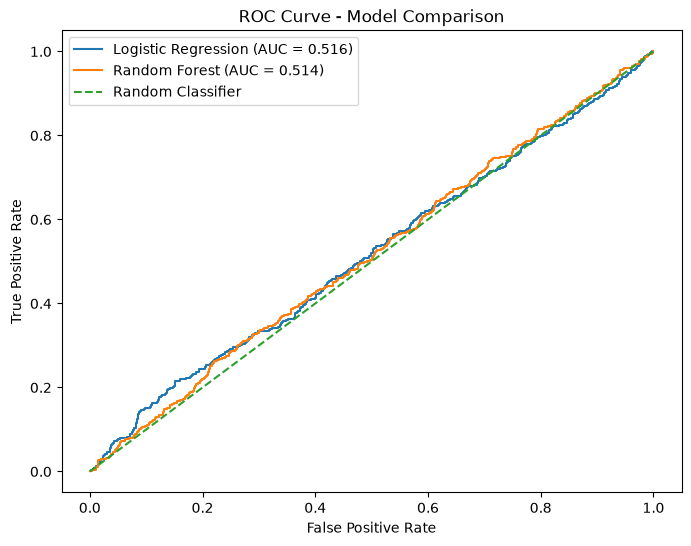

In [57]:
# Plot both ROC curves

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {rf_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Model Comparison")
plt.legend()
plt.show()

##### FINAL MODEL COMPARISON

In [58]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy
    ],
    "Precision": [
        precision,
        rf_precision
    ],
    "Recall": [
        recall,
        rf_recall
    ],
    "F1 Score": [
        f1,
        rf_f1
    ],
    "ROC-AUC": [
        roc_auc,
        rf_roc_auc
    ]
})

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.5345,0.232558,0.468750,0.310881,0.515729
1,Random Forest,0.6460,0.243083,0.274554,0.257862,0.514384


In [59]:
# Round the Final comparison value
final_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.534,0.233,0.469,0.311,0.516
1,Random Forest,0.646,0.243,0.275,0.258,0.514


In [60]:
final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.5345,0.232558,0.468750,0.310881,0.515729
1,Random Forest,0.6460,0.243083,0.274554,0.257862,0.514384


##### PREDICT THE OUTCOME FOE NEW PATIENT

In [61]:
random_forest_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','gender','country',...,'treatment_type','diagnosis_year', 'diagnosis_month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [62]:
x

,age,gender,country,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type,diagnosis_year,diagnosis_month
0,64,Male,Sweden,Stage I,Yes,Passive Smoker,29.4,199,0,0,1,0,Chemotherapy,2016,4
1,50,Female,Netherlands,Stage III,Yes,Passive Smoker,41.2,280,1,1,0,0,Surgery,2023,4
2,65,Female,Hungary,Stage III,Yes,Former Smoker,44.0,268,1,1,0,0,Combined,2023,4
3,51,Female,Belgium,Stage I,No,Passive Smoker,43.0,241,1,1,0,0,Chemotherapy,2016,2
4,37,Male,Luxembourg,Stage I,No,Passive Smoker,19.7,178,0,0,0,0,Combined,2023,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,65,Male,Cyprus,Stage I,Yes,Passive Smoker,33.9,277,1,1,0,0,Combined,2024,5
9996,61,Female,Malta,Stage I,No,Current Smoker,33.2,282,1,0,0,0,Surgery,2015,9
9997,52,Male,Sweden,Stage I,No,Passive Smoker,27.0,156,1,0,0,0,Radiation,2022,11
9998,69,Male,Netherlands,Stage IV,No,Former Smoker,42.6,261,1,1,1,0,Surgery,2021,3


In [63]:
# Create a new patient data for prediction

new_patient = pd.DataFrame({
    "age": [60],
    "gender": ["Male"],
    "country": ["Sweden"],
    "diagnosis_date": [pd.Timestamp("2024-01-15")],
    "cancer_stage": ["Stage II"],
    "family_history": ["Yes"],
    "smoking_status": ["Former Smoker"],
    "bmi": [24.5],
    "cholesterol_level": [190],
    "hypertension": [0],
    "asthma": [1],
    "cirrhosis": [0],
    "other_cancer": [0],
    "treatment_type": ["Chemotherapy"]
})

new_patient

,age,gender,country,diagnosis_date,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type
0,60,Male,Sweden,2024-01-15,Stage II,Yes,Former Smoker,24.5,190,0,1,0,0,Chemotherapy


In [64]:
# DATA PREPROCESSING

new_patient["diagnosis_date"] = pd.to_datetime(
    new_patient["diagnosis_date"],
    errors="coerce"
)

new_patient["diagnosis_year"] = (
    new_patient["diagnosis_date"].dt.year
)

new_patient["diagnosis_month"] = (
    new_patient["diagnosis_date"].dt.month
)


In [65]:
new_patient = new_patient.drop(columns=["diagnosis_date"])

In [66]:
new_patient.dtypes

age                    int64
gender                   str
country                  str
cancer_stage             str
family_history           str
smoking_status           str
bmi                  float64
cholesterol_level      int64
hypertension           int64
asthma                 int64
cirrhosis              int64
other_cancer           int64
treatment_type           str
diagnosis_year         int32
diagnosis_month        int32
dtype: object

In [67]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = new_patient.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = new_patient.select_dtypes(
    include=["string"]
).columns.tolist()

print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)


numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy ="most_frequent"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

random_forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

random_forest_model

Numerical columns: ['age', 'bmi', 'cholesterol_level', 'hypertension', 'asthma', 'cirrhosis', 'other_cancer', 'diagnosis_year', 'diagnosis_month']
Categorical columns: ['gender', 'country', 'cancer_stage', 'family_history', 'smoking_status', 'treatment_type']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [68]:
new_patient

,age,gender,country,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type,diagnosis_year,diagnosis_month
0,60,Male,Sweden,Stage II,Yes,Former Smoker,24.5,190,0,1,0,0,Chemotherapy,2024,1


In [69]:
print(new_patient.columns)

Index(['age', 'gender', 'country', 'cancer_stage', 'family_history',
       'smoking_status', 'bmi', 'cholesterol_level', 'hypertension', 'asthma',
       'cirrhosis', 'other_cancer', 'treatment_type', 'diagnosis_year',
       'diagnosis_month'],
      dtype='str')


In [70]:
print(new_patient.columns.tolist())

['age', 'gender', 'country', 'cancer_stage', 'family_history', 'smoking_status', 'bmi', 'cholesterol_level', 'hypertension', 'asthma', 'cirrhosis', 'other_cancer', 'treatment_type', 'diagnosis_year', 'diagnosis_month']


In [71]:
print(random_forest_model.named_steps.keys())

dict_keys(['preprocessor', 'model'])


In [72]:
print(random_forest_model.named_steps.keys())

print(
    "Model fitted:",
    hasattr(
        random_forest_model.named_steps["model"],
        "estimators_"
    )
)

dict_keys(['preprocessor', 'model'])
Model fitted: False


In [73]:
# Train the model
random_forest_model.fit(x_train, y_train)

print("Model trained successfully!")

# Predict on test data
prediction = random_forest_model.predict(x_test)

# Get probabilities
probability = random_forest_model.predict_proba(x_test)

print("First 10 predictions:", prediction[:10])
print("First 10 probabilities:\n", probability[:10])

Model trained successfully!
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]
First 10 probabilities:
 [[0.79 0.21]
 [0.82 0.18]
 [0.54 0.46]
 [0.65 0.35]
 [0.72 0.28]
 [0.84 0.16]
 [0.81 0.19]
 [0.77 0.23]
 [0.69 0.31]
 [0.73 0.27]]


In [74]:
prediction = random_forest_model.predict(new_patient)[0]

if prediction == 1:
    print("The model predicts class 1 - The patient will not survive.")
elif prediction == 0:
    print("The model predicts class 0 - The patient will survive.")

probabilities = random_forest_model.predict_proba(new_patient)[0]
classes = random_forest_model.named_steps["model"].classes_

print("Predicted outcome:", prediction)


The model predicts class 0 - The patient will survive.
Predicted outcome: 0


In [75]:
import joblib

joblib.dump(
    random_forest_model,
    "lung_cancer_survival_model.pkl"
)

['lung_cancer_survival_model.pkl']

In [76]:
loaded_model = joblib.load(
    "lung_cancer_survival_model.pkl"
)

In [77]:
loaded_model.predict(new_patient)

array([0])

In [78]:
import joblib
import pandas as pd

# Save the feature names and input types
joblib.dump({
    "feature_columns": x_train.columns.tolist(),
    "numeric_columns": x_train.select_dtypes(
        include="number"
    ).columns.tolist(),
    "categorical_columns": x_train.select_dtypes(
        include=["str", "category", "bool"]
    ).columns.tolist(),
    "category_values": {
        col: x_train[col].dropna().unique().tolist()
        for col in x_train.select_dtypes(
            include=["str", "category", "bool"]
        ).columns
    },
    "numeric_defaults": {
        col: float(x_train[col].median())
        for col in x_train.select_dtypes(
            include="number"
        ).columns
    }
}, "model_metadata.pkl")

print("Model and metadata saved successfully!")

Model and metadata saved successfully!


lung_cancer_model.pkl - the trained model and preprocessing pipeline.

model_metadata.pkl — the input feature names, types, categories, and numerical defaults.

##### CLASS IMBALANCE CHECK

In [79]:
print(random_forest_model.classes_)
print(random_forest_model.predict(new_patient))
print(random_forest_model.predict_proba(new_patient))
print(y_train.value_counts())

[0 1]
[0]
[[0.77 0.23]]
survived
0    6210
1    1790
Name: count, dtype: int64


In [80]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = random_forest_model.predict(x_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[1549    3]
 [ 447    1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.87      1552
           1       0.25      0.00      0.00       448

    accuracy                           0.78      2000
   macro avg       0.51      0.50      0.44      2000
weighted avg       0.66      0.78      0.68      2000



In [82]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

balanced_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
balanced_model.fit(x_train, y_train)

# Predict on the test set
y_pred_balanced = balanced_model.predict(x_test)

# Evaluate
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    zero_division=0
))

print(
    "\nBalanced Accuracy:",
    balanced_accuracy_score(y_test, y_pred_balanced)
)

Confusion Matrix:
[[1505   47]
 [ 437   11]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.97      0.86      1552
           1       0.19      0.02      0.04       448

    accuracy                           0.76      2000
   macro avg       0.48      0.50      0.45      2000
weighted avg       0.64      0.76      0.68      2000


Balanced Accuracy: 0.4971350331369661


In [84]:
import pandas as pd

probabilities = balanced_model.predict_proba(x_test)

class_1_index = list(
    balanced_model.classes_
).index(1)

class_1_prob = probabilities[:, class_1_index]

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_balanced,
    "Probability_Class_1": class_1_prob
})

print(results.head(10))

print("\nProbability summary:")
print(results["Probability_Class_1"].describe())

print("\nActual class-wise probability:")
print(
    results.groupby("Actual")["Probability_Class_1"]
    .describe()
)

   Actual  Predicted  Probability_Class_1
0       0          0                0.335
1       0          0                0.295
2       0          0                0.435
3       0          0                0.485
4       1          0                0.395
5       1          0                0.340
6       0          0                0.290
7       1          0                0.500
8       0          0                0.440
9       1          0                0.275

Probability summary:
count    2000.000000
mean        0.353038
std         0.074065
min         0.170000
25%         0.300000
50%         0.350000
75%         0.400000
max         0.635000
Name: Probability_Class_1, dtype: float64

Actual class-wise probability:
         count      mean       std    min    25%     50%    75%    max
Actual                                                                
0       1552.0  0.352613  0.074719  0.170  0.300  0.3500  0.400  0.635
1        448.0  0.354509  0.071819  0.185  0.305  0.3475  0.4

In [85]:
print("Original target distribution:")
print(y.value_counts())

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

Original target distribution:
survived
0    7762
1    2238
Name: count, dtype: int64

Training target distribution:
survived
0    6210
1    1790
Name: count, dtype: int64

Test target distribution:
survived
0    1552
1     448
Name: count, dtype: int64


In [86]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = random_forest_model.predict(x_test)

print("Actual values:")
print(y_test.value_counts())

print("\nPredicted values:")
print(pd.Series(y_pred).value_counts())

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Actual values:
survived
0    1552
1     448
Name: count, dtype: int64

Predicted values:
0    1996
1       4
Name: count, dtype: int64

Confusion Matrix:
[[1549    3]
 [ 447    1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.87      1552
           1       0.25      0.00      0.00       448

    accuracy                           0.78      2000
   macro avg       0.51      0.50      0.44      2000
weighted avg       0.66      0.78      0.68      2000



In [87]:
probabilities = random_forest_model.predict_proba(x_test)

print("Classes:", random_forest_model.classes_)
print("First 10 probabilities:")
print(probabilities[:10])

print("First 10 predictions:")
print(random_forest_model.predict(x_test[:10]))

Classes: [0 1]
First 10 probabilities:
[[0.79 0.21]
 [0.82 0.18]
 [0.54 0.46]
 [0.65 0.35]
 [0.72 0.28]
 [0.84 0.16]
 [0.81 0.19]
 [0.77 0.23]
 [0.69 0.31]
 [0.73 0.27]]
First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]
